## Imports

In [15]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sys
from pathlib import Path
from types import SimpleNamespace
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
from scipy.stats import gaussian_kde
from collections import Counter
from matplotlib.backends.backend_pdf import PdfPages

# Add the parent of mixture_density_network to sys.path
project_root = Path().absolute().parent  # points to Madidi_forest_analysis
sys.path.append(str(project_root))
print("Added to sys.path:", project_root)
from mixture_density_network.src.blocks import MixtureDensityNetwork, NoiseType
from mixture_density_network.training.train import LitModel

Added to sys.path: /stor/work/Wilke/kelly/Madidi_forest_analysis


## Device Configuration

In [16]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
device

device(type='cpu')

## Load Data and Model

In [17]:
interests = ["DrySeasonDeficit", "ResinPi", "TotalP"]
base_dir_name = "batch32_epochs100_lr0.0004_weightdecay1e-06_beta10.9_beta20.95_dropout0.1_numcomponents15_hidden64"

# Split by underscores
parts = base_dir_name.split("_")
# Extract parameters
params = {}
for part in parts:
    if part.startswith("batch"): params["batch_size"] = int(part.replace("batch", ""))
    elif part.startswith("epochs"): params["epochs"] = int(part.replace("epochs", ""))
    elif part.startswith("lr"): params["learn_rate"] = float(part.replace("lr", ""))
    elif part.startswith("weightdecay"): params["weight_decay"] = float(part.replace("weightdecay", ""))
    elif part.startswith("beta1"): params["beta1"] = float(part.replace("beta1", ""))
    elif part.startswith("beta2"): params["beta2"] = float(part.replace("beta2", ""))
    elif part.startswith("dropout"): params["dropout"] = float(part.replace("dropout", ""))
    elif part.startswith("numcomponents"): params["num_components"] = int(part.replace("numcomponents", ""))
    elif part.startswith("hidden"): params["hidden_size"] = int(part.replace("hidden", ""))
    elif part.startswith("rarity"): params["rarity_threshold"] = int(part.replace("rarity", ""))
        
# Default rarity_threshold to None if not found
params["rarity_threshold"] = params.get("rarity_threshold", None)

print(params)

{'batch_size': 32, 'epochs': 100, 'learn_rate': 0.0004, 'weight_decay': 1e-06, 'beta1': 0.9, 'beta2': 0.95, 'dropout': 0.1, 'num_components': 15, 'hidden_size': 64, 'rarity_threshold': None}


In [ ]:
interests_data = {}
log_interests = {"ResinPi", "TotalP"}

for interest in interests:    

    use_log = interest in log_interests

    # Build directory name conditionally
    current_dir_name = base_dir_name + ("_log" if use_log else "")

    # Define directories
    data_dir = Path(f"../training_output/{interest}/{current_dir_name}")
    output_dir = Path(f"figures/{current_dir_name}")
    print(f"{interest}: using {'log' if use_log else 'raw'} data")

    # Pick the checkpoint with the lowest validation loss
    checkpoint_files = list((data_dir / "checkpoints").glob("checkpoint_epoch=*_val_loss=*.ckpt"))
    best_checkpoint = min(checkpoint_files, key=lambda p: float(p.name.split("val_loss=")[-1].replace(".ckpt", "").split("_")[0]))

    # Extract best epoch 
    best_epoch = int(best_checkpoint.name.split("checkpoint_epoch=")[-1].split("_")[0])
    print(f"Best epoch for {interest}: {best_epoch}")

    # Load dataset
    rarity_suffix = f"_rarity{params['rarity_threshold']}" if params["rarity_threshold"] else ""
    if use_log:
        dataset_path = Path(f"../data/processed_datasets/dataset_{interest}{rarity_suffix}_log.pt")
    else:
        dataset_path = Path(f"../data/processed_datasets/dataset_{interest}{rarity_suffix}.pt")
    dataset = torch.load(dataset_path)
    X_train = dataset["train"]["embedding"].to(device)
    y_train = dataset["train"][interest].to(device)
    X_val = dataset["val"]["embedding"].to(device)
    y_val = dataset["val"][interest].to(device)
    X_test = dataset["test"]["embedding"].to(device)
    y_test = dataset["test"][interest].to(device)

    # Build train/test DataFrames 
    train_df = pd.DataFrame({
        'FEATURE_ID': dataset['train']['FEATURE_ID'],
        interest: dataset['train'][interest].cpu().numpy(),
        'embedding': list(dataset['train']['embedding'].cpu().numpy())
    })

    test_df = pd.DataFrame({
        'FEATURE_ID': dataset['test']['FEATURE_ID'],
        interest: dataset['test'][interest].cpu().numpy(),
        'embedding': list(dataset['test']['embedding'].cpu().numpy())
    })

    # Load model
    args = SimpleNamespace(
        data_file=str(dataset_path),
        lr=params["learn_rate"],
        weight_decay=params["weight_decay"],
        batch_size=params["batch_size"],
        epochs=params["epochs"],
        beta1=params["beta1"],
        beta2=params["beta2"],
        dropout=params["dropout"],
        num_components=params["num_components"],
        hidden_dim=params["hidden_size"],
    )
    model_module = LitModel.load_from_checkpoint(checkpoint_path=str(best_checkpoint), args=args, map_location=device,)
    model = model_module.model.to(device)
    model.eval()

    # Generate predictions
    with torch.no_grad():
        y_hat = model.sample(X_test)

    # Reverse normalization
    y_mean = torch.tensor(train_df[interest].values, dtype=torch.float32).mean().item()
    y_std = torch.tensor(train_df[interest].values, dtype=torch.float32).std().item()
    y_hat_unnormalized = y_hat * y_std + y_mean
    
    y_test_unsq = y_test.unsqueeze(1)

    # Rarity distribution
    all_splits = []
    for split in ['train', 'val', 'test']:
        df_split = pd.DataFrame({'FEATURE_ID': dataset[split]['FEATURE_ID'].numpy()})
        all_splits.append(df_split)
    all_df = pd.concat(all_splits, ignore_index=True)
    feature_counts = all_df['FEATURE_ID'].value_counts().reset_index()
    feature_counts.columns = ['FEATURE_ID', 'num_plots']
    rarity_threshold = 4
    feature_counts['rarity'] = ['Rare' if n <= rarity_threshold else 'Common' for n in feature_counts['num_plots']]

    # Store everything
    interests_data[interest] = {
        "dataset": dataset,
        "best_epoch": best_epoch,
        "train_df": train_df,
        "test_df": test_df,
        "X_test": X_test,
        "y_test": y_test_unsq,
        "y_hat": y_hat_unnormalized,
        "feature_counts": feature_counts,
        "output_dir": output_dir,
        "model": model, 
    }

DrySeasonDeficit: using raw data
Best epoch for DrySeasonDeficit: 13
ResinPi: using log data
Best epoch for ResinPi: 2
TotalP: using log data
Best epoch for TotalP: 2


In [19]:
normal_names = {
    "DrySeasonDeficit": "Dry-Season Moisture",
    "ResinPi": "Log Resin Phosphorus",
    "TotalP": "Log Total Phosphorus",
}

In [20]:
def darken_color(color, amount):
    """
    Darken the given color by multiplying (1-luminosity) by amount
    """
    c = mcolors.to_rgb(color)
    return tuple(max(min(comp * amount, 1), 0)for comp in c)

## Plot Rarity Distribution

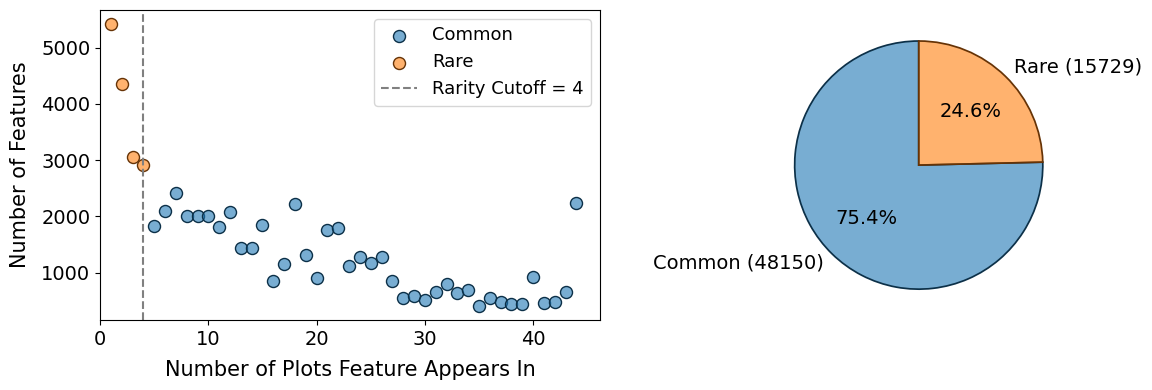

In [ ]:
# Get the data for one interest (they are all the same)
interest, data = next(iter(interests_data.items()))
feature_counts = data["feature_counts"]

# Prep data for scatterplot
scatter_data = feature_counts.groupby('num_plots').size().reset_index(name='count')
scatter_data['rarity'] = scatter_data['num_plots'].apply(lambda x: 'Rare' if x <= rarity_threshold else 'Common')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {"Rare": "tab:orange", "Common": "tab:blue"}

# Scatterplot on the left
for rarity, subset in scatter_data.groupby('rarity'):
    color = colors[rarity]
    fill = mcolors.to_rgba(color, alpha=0.6)
    edge = darken_color(color, amount=0.4)
    axes[0].scatter(
        subset['num_plots'],
        subset['count'],
        label=rarity,
        s=75,
        facecolors=fill,
        edgecolors=edge, 
        linewidths=1
    )

axes[0].axvline(rarity_threshold, color='gray', linestyle='--', label=f'Rarity Cutoff = {rarity_threshold}')
axes[0].set_xlabel('Number of Plots Feature Appears In', fontsize=15, labelpad=8)
axes[0].set_xlim(left=0)
axes[0].set_ylabel('Number of Features', fontsize=15, labelpad=8)
axes[0].tick_params(axis='both', labelsize=14)
axes[0].legend(fontsize=13, title=None)

# Pie chart on the right
rarity_counts = feature_counts['rarity'].value_counts()
wedges, texts, autotexts = axes[1].pie(
    rarity_counts,
    labels=[f"{label} ({count})" for label, count in rarity_counts.items()],
    autopct="%1.1f%%",
    startangle=90,
    colors=[colors['Common'], colors['Rare']],
    wedgeprops={'linewidth': 1.25}
)

# Apply transparency and darker edges
for w, c in zip(wedges, [colors['Common'], colors['Rare']]):
    rgba = mcolors.to_rgba(c, alpha=0.6)
    w.set_facecolor(rgba)
    w.set_edgecolor(darken_color(c, amount=0.4))

# Font sizes
for t in texts + autotexts:
    t.set_fontsize(14)

# # Add letter labels
# labels = ["a", "b"]
# for ax, label in zip(axes, labels): 
#     ax.annotate(f"{label}", xy=(-0.03, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

plt.tight_layout()
plt.savefig("figures/rarity_distribution.pdf", dpi=300)
plt.show()

## Plot Loss

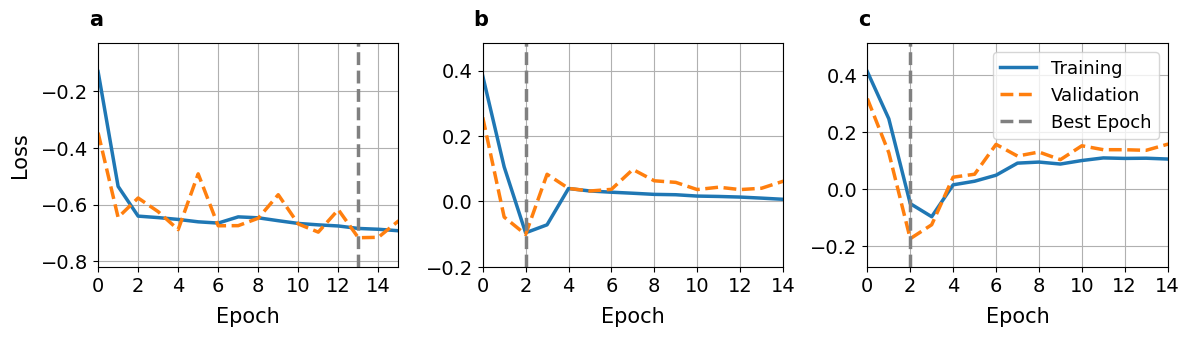

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes = axes.flatten()
labels = ['a', 'b', 'c']

for ax, (interest, data), label in zip(axes, interests_data.items(), labels):
    output_dir = data["output_dir"]
    current_dir_name = base_dir_name + ("_log" if interest in log_interests else "")
    data_dir = Path(f"../training_output/{interest}/{current_dir_name}")

    metrics_csv = data_dir / "training/version_0/metrics.csv"
    metrics = pd.read_csv(metrics_csv)

    train_losses = metrics[['epoch', 'train_loss']].dropna().sort_values('epoch')
    val_losses = metrics[['epoch', 'val_loss']].dropna().sort_values('epoch')

    epochs = train_losses['epoch'].values
    ax.plot(epochs, train_losses['train_loss'], label='Training', color='tab:blue', linewidth=2.5)
    ax.plot(epochs, val_losses['val_loss'], label='Validation', color='tab:orange', linestyle='--', linewidth=2.5)

    ax.tick_params(labelsize=14)
    ax.grid(True)

    # Add vertical line at best epoch
    ax.axvline(data["best_epoch"], color='gray', linestyle='--', label='Best Epoch', linewidth=2.5)

    # Set x-axis a bit beyond the best checkpoint epoch
    buffer = 2  # extra epochs past best
    ax.set_xlim(left=0, right=data["best_epoch"] + buffer)

    # Expand y-limits to leave space for legend
    y_max = max(train_losses['train_loss'].max(), val_losses['val_loss'].max())
    y_min = min(train_losses['train_loss'].min(), val_losses['val_loss'].min())
    ax.set_ylim(y_min - 0.1, y_max + 0.1)

    ax.set_xlabel('Epoch', fontsize=15, labelpad=8)

    # Only show y-label on the first subplot
    if ax == axes[0]:
        ax.set_ylabel('Loss', fontsize=15, labelpad=8)

    # Only show legend on the last subplot
    if ax == axes[-1]:
        ax.legend(fontsize=13, loc='upper right')
 
    # Add letter labels
    ax.annotate(f"{label}", xy=(-0.03, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

# Define consistent x-ticks starting at 0
x_min = 0
x_max = max(ax.get_xlim()[1] for ax in axes)  
x_ticks = np.arange(x_min, x_max + 1, step=2)  
for ax in axes:
    ax.set_xticks(x_ticks)

plt.tight_layout()  
plt.savefig("figures/combined_loss_all.pdf", dpi=300)
plt.show()

## Plot Distribution + Model's Recreation

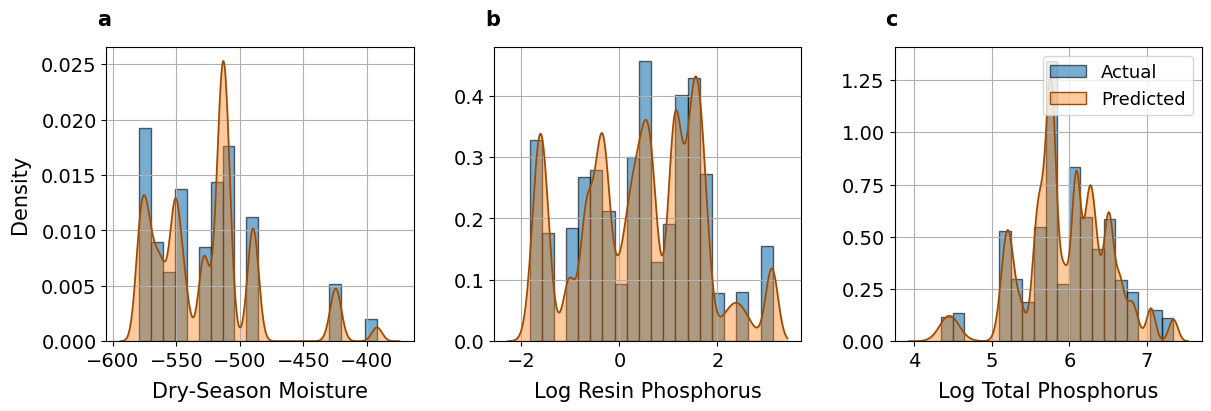

In [ ]:
labels = ["a", "b", "c"]
num_interests = len(interests_data)

fig, axes = plt.subplots(
    1, num_interests,
    figsize=(12, 4),
    constrained_layout=True,
    gridspec_kw={'wspace': 0.1}
)

if num_interests == 1:
    axes = [axes]

for i, (ax, (interest, data), label) in enumerate(zip(axes, interests_data.items(), labels)):
    y_test = data["y_test"]
    y_hat = data["y_hat"]

    actual = y_test[:, 0].cpu().numpy()
    predicted = y_hat[:, 0].cpu().numpy()

    # Histogram
    ax.hist(actual, bins=20, alpha=0.6, label='Actual', density=True, color='tab:blue', edgecolor='black')

    # KDE 
    kde = gaussian_kde(predicted)
    x_margin = (predicted.max() - predicted.min()) * 0.05  # 5% margin
    x_vals = np.linspace(predicted.min() - x_margin, predicted.max() + x_margin, 500)
    kde_vals = kde(x_vals)
    ax.fill_between(x_vals, kde_vals, color=mcolors.to_rgba('tab:orange', 0.4))
    ax.plot(x_vals, kde_vals, color=darken_color('tab:orange', amount=0.6), linewidth=1.25)

    ax.set_xlabel(normal_names.get(interest, interest), fontsize=15, labelpad=8)
    ax.set_ylabel('Density', fontsize=15, labelpad=8)
    ax.tick_params(axis='both', labelsize=14)
    ax.grid(True)

    # Only show y-label on the first subplot
    if i != 0:
        ax.set_ylabel('')

    # Only show legend on the last subplot
    if i == (num_interests - 1):
        # Create KDE proxy
        kde_proxy = mpatches.Patch(facecolor=mcolors.to_rgba('tab:orange', 0.4), edgecolor=darken_color('tab:orange', amount=0.6), label='Predicted')
        handles, labels = ax.get_legend_handles_labels()
        handles.append(kde_proxy)
        ax.legend(handles=handles, fontsize=13, loc='upper right')

    # Add letter labels
    ax.annotate(f"{label}", xy=(-0.03, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

plt.savefig("figures/combined_distribution_all.pdf", dpi=300)
plt.show()

## Plot Model Predictions

In [24]:
def get_predictions(embedding, num_samples, pred_cache, feature_id, model, device, interest):
    
    cache_key = (interest, feature_id)
    
    if cache_key not in pred_cache:
        pred_cache[cache_key] = {}
    
    # check if predictions for this feature and sample size are already cached
    if num_samples not in pred_cache[cache_key]:
        emb = torch.tensor(embedding, dtype=torch.float32).unsqueeze(0).repeat(num_samples, 1).to(device)
        with torch.no_grad():
            preds = model.sample(emb).cpu().numpy()
        pred_cache[cache_key][num_samples] = pd.DataFrame(preds, columns=[interest])
    
    return pred_cache[cache_key][num_samples]

In [25]:
# Plotting for each feature
def plot_feature_actual_vs_predicted(actual_values, pred_vals, feature_id, interest, ax, shared_bins, xmin, xmax, ymax, kde_bw):
    """Plot actual values as vertical lines with horizontal jitter for duplicates,
    and KDE of predictions for a single FEATURE_ID."""
 
    # Plot KDE of predicted values with shared x-axis if provided
    if xmin is None:                                              
        x_vals = np.linspace(pred_vals.min(), pred_vals.max(), 500)
    else:
        x_vals = np.linspace(xmin, xmax, 500)

    kde = gaussian_kde(pred_vals, bw_method=kde_bw)
    kde_vals = kde(x_vals)

    ax.fill_between(x_vals, kde_vals, color='tab:orange', alpha=0.4, zorder=2)
    ax.plot(x_vals, kde_vals, color=darken_color('tab:orange', amount=0.5), linewidth=1, zorder=2)

    # If there is only one actual value, plot vertical line
    if len(actual_values) == 1 or np.allclose(actual_values, actual_values[0]):
        # Rug for actual values
        jitter = (np.random.rand(len(actual_values)) - 0.5) * 0.01
        sns.rugplot(actual_values + jitter, ax=ax, color='tab:blue', linewidth=2.5, height=1, zorder=1)

    else:
        # Plot histogram of actual values with shared bins if provided
        if shared_bins is not None:                  
            bins = shared_bins
        else:
            data_min, data_max = actual_values.min(), actual_values.max()
            data_range = data_max - data_min
            binwidth = data_range / 15 if data_range > 0 else 1
            bins = np.arange(data_min, data_max + binwidth, binwidth)

        ax.hist(actual_values, bins=bins, color='tab:blue', alpha=0.6, label='Actual', density=True, edgecolor='black')

    # Apply shared axis limits for the row
    if xmin is not None:                           
        ax.set_xlim(xmin, xmax)
    if ymax is not None:
        ax.set_ylim(0, ymax)

    # Labels, title, and styling
    ax.set_xlabel(normal_names.get(interest, interest), fontsize=15, labelpad=8)
    ax.set_ylabel('Density', fontsize=15, labelpad=8)
    ax.set_title(f'Feature ID {feature_id}', fontsize=14)
    ax.tick_params(axis='both', labelsize=14)
    ax.grid(True)

    # Only show legend in the top right plot
    if ax.get_subplotspec().rowspan.start == 0 and ax.get_subplotspec().colspan.start == 2:
        kde_proxy = mpatches.Patch(facecolor=mcolors.to_rgba('tab:orange', 0.4), edgecolor=darken_color('tab:orange', amount=0.6), label='Predicted')
        handles, labels = ax.get_legend_handles_labels()
        handles.append(kde_proxy)
        ax.legend(handles=handles, fontsize=13, loc='upper right')

Feature usage counts:
  98770: 44 times
  80192: 21 times
  85874: 24 times
  70227: 26 times
  36246: 43 times
  46968: 32 times
  100989: 26 times
  95911: 23 times
  27487: 40 times


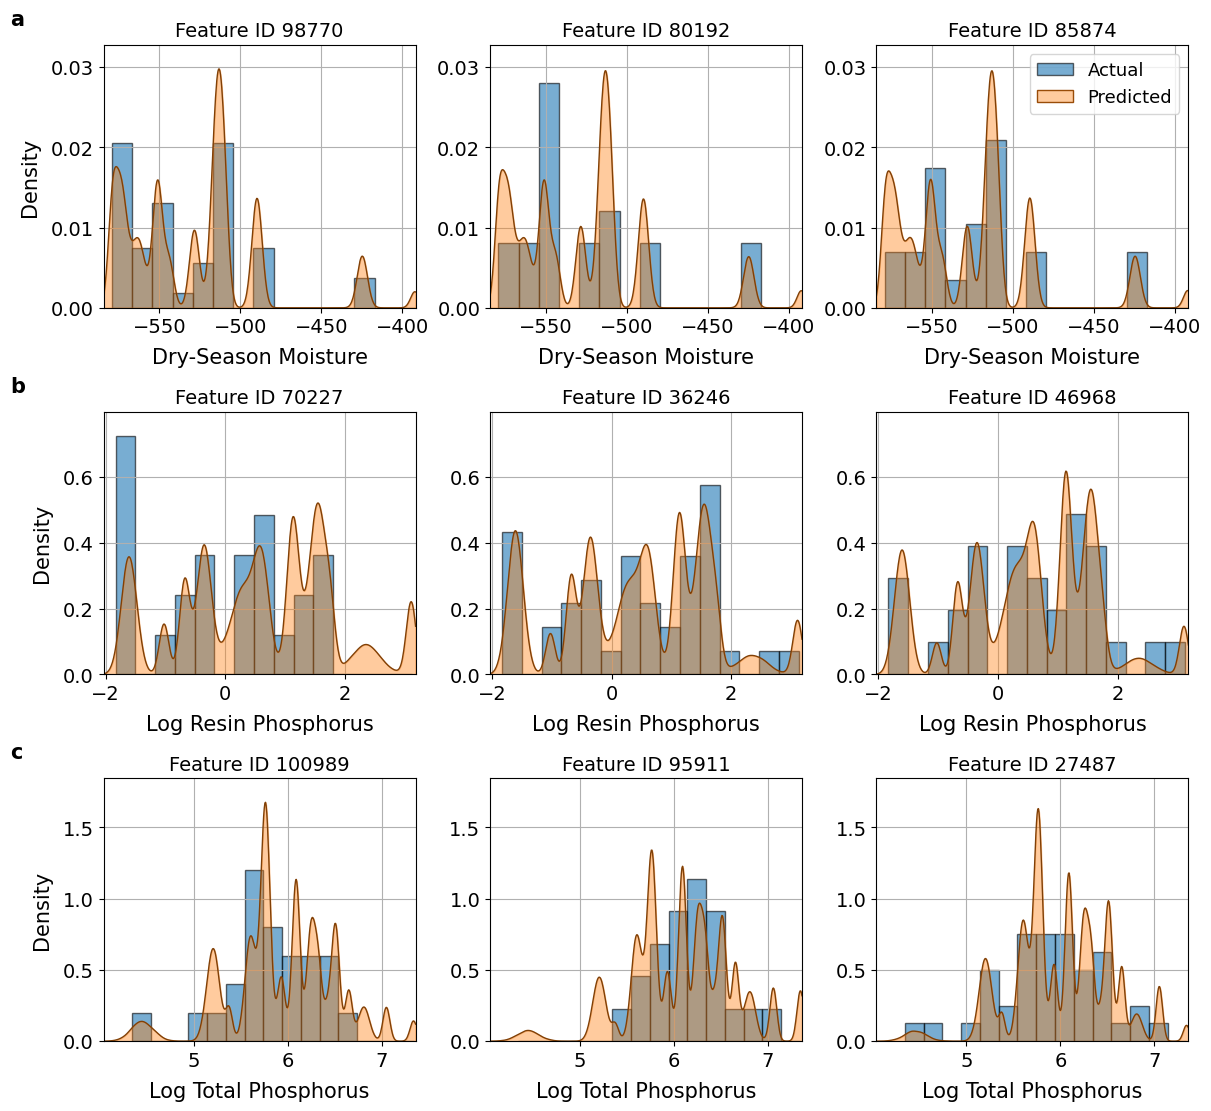

In [ ]:
feature_counts = Counter()
num_features_per_interest = 3  # 3 random features per interest
interests = list(interests_data.keys())
num_interests = len(interests)

pred_cache = {}

fig, axes = plt.subplots(num_interests, num_features_per_interest, figsize=(12, 11), constrained_layout=True)

for row, interest in enumerate(interests):
    # Choose features
    data = interests_data[interest]
    model = data["model"]
    test_df = data["test_df"]
    train_df = data["train_df"]

    random_features = test_df['FEATURE_ID'].sample(n=num_features_per_interest).unique()
    y_mean, y_std = train_df[interest].mean(), train_df[interest].std()

    feature_data_for_plot = {}
    all_actual, all_pred = [], []

    # First pass: compute shared x/y limits and collect data for plotting
    for feature_id in random_features:
        fdata = test_df[test_df['FEATURE_ID'] == feature_id]

        # Count the number of plots this feature appears in
        feature_counts[feature_id] += len(fdata)

        # Collect actual
        actual_vals = fdata[interest].values
        all_actual.append(actual_vals)

        # Collect predicted
        embedding = fdata['embedding'].iloc[0]
        preds_df = get_predictions(embedding, num_samples=100000, pred_cache=pred_cache, feature_id=feature_id, model=model, device=device, interest=interest)

        # Unnormalize and store for range calculation
        pred_vals = (preds_df[interest] * y_std + y_mean).values
        all_pred.append(pred_vals)
        
        # Store for the second pass
        feature_data_for_plot[feature_id] = {'actual_vals': actual_vals, 'pred_vals': pred_vals}

    # Flatten lists for shared ranges
    all_actual_flat = np.concatenate(all_actual)
    all_pred_flat = np.concatenate(all_pred)

    ##### Step 2: Compute Shared X Range and Bins
    
    # Compute shared bins
    data_min, data_max = all_actual_flat.min(), all_actual_flat.max()
    data_range = data_max - data_min
    if data_range == 0:
        data_range = 1
    binwidth = data_range / 15
    shared_bins = np.arange(data_min, data_max + binwidth, binwidth)

    # Shared x range
    row_xmin = min(all_actual_flat.min(), all_pred_flat.min())
    row_xmax = max(all_actual_flat.max(), all_pred_flat.max())

    # Shared KDE bandwidth
    global_kde = gaussian_kde(all_pred_flat)
    global_bw = global_kde.factor * 0.8

    ##### Compute Shared Y Range
    
    # Calculate max peak across all individual feature plots
    all_peaks = [] 
    x_grid = np.linspace(row_xmin, row_xmax, 500)

    for feature_id in random_features:
        data_point = feature_data_for_plot[feature_id]
        actual_vals = data_point['actual_vals']
        pred_vals = data_point['pred_vals']

        # Individual Actual Histogram Peak
        # Only check peak if plotting histogram (not a rugplot/single line)
        if len(actual_vals) > 1 and not np.allclose(actual_vals, actual_vals[0]):
            hist_counts, _ = np.histogram(actual_vals, bins=shared_bins, density=True)
            all_peaks.append(hist_counts.max())

        # Individual Predicted KDE Peak
        kde = gaussian_kde(pred_vals, bw_method=global_bw)
        all_peaks.append(kde(x_grid).max())

    # Set shared max Y limit based on maximum individual peak
    if all_peaks:
        row_ymax = max(all_peaks) * 1.1 # Apply buffer for padding
    else:
        row_ymax = 1.0 # Fallback 

    ##### Create Subplots
    for col, feature_id in enumerate(random_features):
        ax = axes[row, col]
        data_point = feature_data_for_plot[feature_id]
        plot_feature_actual_vs_predicted(data_point['actual_vals'], data_point['pred_vals'], feature_id, interest, ax, shared_bins, row_xmin, row_xmax, row_ymax, global_bw)

        # Only show y-label on first column
        if col != 0:    
            ax.set_ylabel('')

# Add row letters (a, b, c) on the left of each row
row_letters = ["a", "b", "c"]
for row, letter in enumerate(row_letters):
    ax = axes[row, 0]  # first column
    ax.annotate(f"{letter}", xy=(-0.3, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

print("Feature usage counts:")
for fid, count in feature_counts.items():
    print(f"  {fid}: {count} times")

plt.savefig(f"figures/actual_vs_predicted_3x3_random_all.pdf", dpi=300)
plt.show()

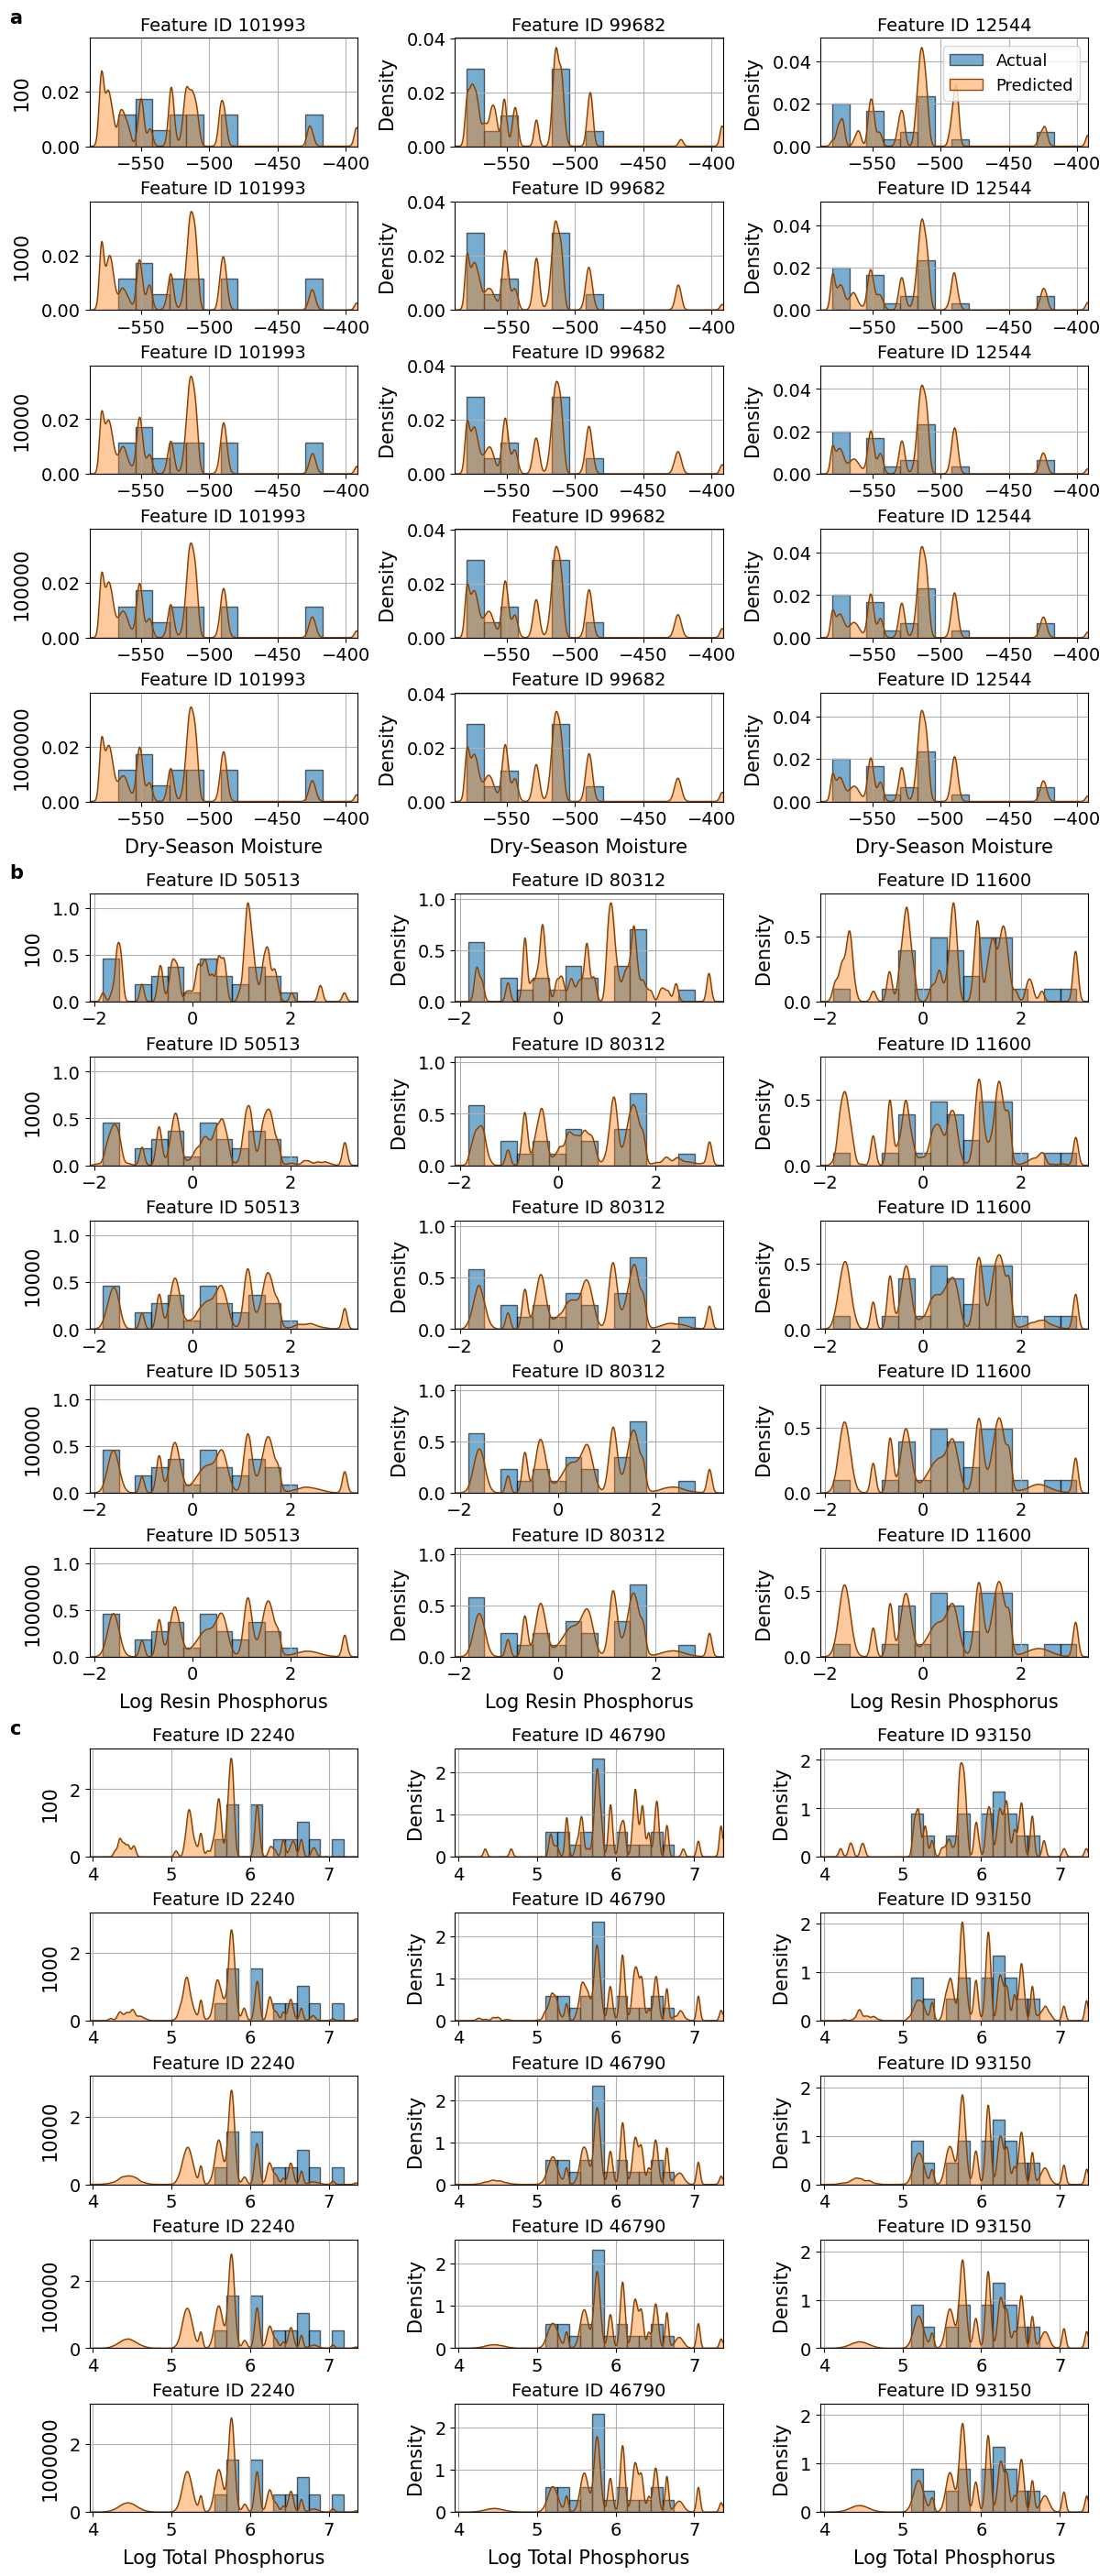

In [ ]:
feature_counts = Counter()
num_features_per_interest = 3
num_samples_list = [100, 1000, 10000, 100000, 1000000]

interests = list(interests_data.keys())
num_interests = len(interests)

pred_cache = {}

# NEW: 3 stacked plots per feature
fig, axes = plt.subplots(
    num_interests * len(num_samples_list),
    num_features_per_interest,
    figsize=(12, 28),
    constrained_layout=True
)

# Helper: index into big axes grid
def get_ax(interest_row, sample_idx, feature_col):
    row = interest_row * len(num_samples_list) + sample_idx
    return axes[row, feature_col]

# Loop over interests
for interest_row, interest in enumerate(interests):

    data = interests_data[interest]
    model = data["model"]
    test_df = data["test_df"]
    train_df = data["train_df"]

    # Fix chosen features ONCE so comparisons match
    random_features = test_df["FEATURE_ID"].sample(num_features_per_interest).unique()

    # Precompute normalization factors
    y_mean = train_df[interest].mean()
    y_std = train_df[interest].std()

    # --- For each interest, compute shared X-range across all features AND all sample sizes ---
    all_actual = []
    all_pred_all_sizes = []

    # First pass: gather actual and pred for X-range
    for feature_id in random_features:
        fdata = test_df[test_df["FEATURE_ID"] == feature_id]

        actual_vals = fdata[interest].values
        all_actual.append(actual_vals)

        embedding = fdata["embedding"].iloc[0]

        # Collect predictions for all three sample sizes to fix shared x-range
        for num_samples in num_samples_list:
            preds = get_predictions(embedding, num_samples=num_samples, pred_cache=pred_cache, feature_id=feature_id, model=model, device=device, interest=interest)
            pred_vals = preds[interest] * y_std + y_mean
            all_pred_all_sizes.append(pred_vals.values)

    # Flatten
    all_actual_flat = np.concatenate(all_actual)
    all_pred_flat = np.concatenate(all_pred_all_sizes)

    row_xmin = min(all_actual_flat.min(), all_pred_flat.min())
    row_xmax = max(all_actual_flat.max(), all_pred_flat.max())

    # Determine bins for this interest
    data_min = all_actual_flat.min()
    data_max = all_actual_flat.max()
    data_range = data_max - data_min if data_max > data_min else 1
    binwidth = data_range / 15
    shared_bins = np.arange(data_min, data_max + binwidth, binwidth)

    # Shared KDE bandwidth
    global_kde = gaussian_kde(all_pred_flat)
    global_bw = global_kde.factor * 0.8

    # === Second pass: plot for each feature and each num_samples ===
    for feature_col, feature_id in enumerate(random_features):

        fdata = test_df[test_df["FEATURE_ID"] == feature_id]
        actual_vals = fdata[interest].values
        embedding = fdata["embedding"].iloc[0]

        # Count feature usage
        feature_counts[feature_id] += len(fdata)

        # Compute shared Y limit across the 3 sample sizes
        peaks = []

        # Actual histogram peak
        if len(actual_vals) > 1 and not np.allclose(actual_vals, actual_vals[0]):
            hist_counts, _ = np.histogram(actual_vals, bins=shared_bins, density=True)
            peaks.append(hist_counts.max())

        # Predicted KDE peaks for each sample size
        for num_samples in num_samples_list:
            preds = get_predictions(embedding, num_samples=num_samples, pred_cache=pred_cache, feature_id=feature_id, model=model, device=device, interest=interest)
            preds_vals = preds[interest] * y_std + y_mean
            pred_vals = preds_vals.values

            kde = gaussian_kde(pred_vals, bw_method=global_bw)
            kde_vals = kde(np.linspace(row_xmin, row_xmax, 500))
            peaks.append(kde_vals.max())

        row_ymax = max(peaks) * 1.1 if peaks else 1.0

        # Now plot three stacked panels
        for sample_idx, num_samples in enumerate(num_samples_list):

            ax = get_ax(interest_row, sample_idx, feature_col)

            preds_df = get_predictions(embedding, num_samples=num_samples, pred_cache=pred_cache, feature_id=feature_id, model=model, device=device, interest=interest)
            pred_vals = (preds_df[interest] * y_std + y_mean).values

            plot_feature_actual_vs_predicted(
                actual_values=actual_vals,
                pred_vals=pred_vals,
                feature_id=feature_id,
                interest=interest,
                ax=ax,
                shared_bins=shared_bins,
                xmin=row_xmin,
                xmax=row_xmax,
                ymax=row_ymax,
                kde_bw=global_bw
            )

            # Label left-side panels
            if feature_col == 0:
                ax.set_ylabel(f"{num_samples}")

            # Clean x labels except bottom panel
            if sample_idx != len(num_samples_list) - 1:
                ax.set_xlabel("")

# Add row letters for interests only (top panel of each interest block)
row_letters = ["a", "b", "c"]
for i, letter in enumerate(row_letters):
    ax = axes[i * len(num_samples_list), 0]
    ax.annotate(
        f"{letter}",
        xy=(-0.3, 1.1),
        xycoords="axes fraction",
        fontsize=15,
        fontweight="bold",
        va="bottom",
        ha="left"
    )

plt.savefig("figures/actual_vs_predicted_sample_comparison.pdf", dpi=300)
plt.show()